In [1]:
import pandas as pd
import numpy as np
import glob
import os
import matplotlib.pyplot as plt
import customfunctions as ctf
from scipy import signal
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from brainflow.data_filter import DataFilter, WindowOperations
import mne
import mne_connectivity as mnec
from mne_connectivity.viz import plot_sensors_connectivity

from itertools import combinations, product


In [2]:
# Working path
folder = 'Rawdata'
cwd = os.getcwd()
folderpath = os.path.join(cwd,folder)
print(folderpath)


c:\Users\josee\OneDrive\Documentos\GitHub\NeuroHAD2025\FILAnalysis\Rawdata


In [3]:
# Sessions of interest
sessions = [2, 12, 14, 21, 27, 28, 31, 39, 41, 42]
# Stages
stages = ["baseline", "shared", "individual"]
# Se guardan los datos de las sesiones en un diccionario
preprodata = {
    "p1": {"baseline": [], "shared": [], "individual": []},
    "p2": {"baseline": [], "shared": [], "individual": []},
}

for stage in stages:
    p1holder = []
    p2holder = []
    for sn in sessions:
        p1 = []
        p2 = []
        pattern = f"S{sn}R*"
        snpath = glob.glob(os.path.join(folderpath, pattern))[0]

        p1 = (
            pd.read_csv(os.path.join(snpath, "processed", f"p1_{stage}.csv"))
            .drop(["Unnamed: 0","board_ts","unix_ts"], axis=1)
            .replace(["Unnamed: 0","board_ts","unix_ts"], np.nan)
            .dropna()
            .apply(pd.to_numeric, axis=0)
        )
        if stage == 'baseline':
            p1 = p1.iloc[2561:25601,:]
        else:
            p1 = p1.iloc[2561:64001,:]
        p1.subtract(p1.mean(axis=1), axis=0) # Common mean reference
        p1.insert(loc=0, column="Session", value=np.ones([p1.shape[0], 1]) * sn)
        p1holder.append(p1)
        p2 = (
            pd.read_csv(os.path.join(snpath, "processed", f"p2_{stage}.csv"))
            .drop(["Unnamed: 0","board_ts","unix_ts"], axis=1)
            .replace(["Unnamed: 0","board_ts","unix_ts"], np.nan)
            .dropna()
            .apply(pd.to_numeric, axis=0)
        )
        if stage == 'baseline':
            p2 = p2.iloc[2561:25601,:]
        else:
            p2 = p2.iloc[2561:64001,:]
        p2.subtract(p2.mean(axis=1), axis=0)
        p2.insert(loc=0, column="Session", value=np.ones([p2.shape[0], 1]) * sn)
        p2holder.append(p2)
    p1holder_df = pd.concat(p1holder, ignore_index=True)
    p2holder_df = pd.concat(p2holder, ignore_index=True)
    preprodata["p1"].update({stage:p1holder_df})
    preprodata["p2"].update({stage:p2holder_df})

In [4]:
preprodata['p2']['baseline'][ preprodata['p1']['baseline']['Session'] == 41 ]

,Session,TP9,AF7,AF8,TP10
184320,41.0,6.283599,9.033713,-5.895783,-25.784886
184321,41.0,3.790505,7.823831,-9.203100,-33.227550
184322,41.0,-5.006978,4.468822,-9.762994,-32.378601
184323,41.0,-17.859640,-0.774919,-7.069969,-26.946536
184324,41.0,-28.629580,-6.175805,-4.470735,-23.317676
...,...,...,...,...,...
207355,41.0,38.136049,-30.470081,-17.548078,39.400611
207356,41.0,60.011499,-22.421810,-39.473445,58.071335
207357,41.0,45.823451,8.910796,-33.432287,46.696319
207358,41.0,1.850072,25.084634,-1.048385,5.365356


In [5]:
fs = 256
winsz = 1 
stages = ["baseline", "shared", "individual"]
channels = ["TP9", "TP10", "AF7", "AF8"]
BANDS = [
    ("theta", 4.0, 8.0),
    ("alpha", 8.0, 13.0),
    ("beta", 13.0, 30.0),
    ("gamma", 30.0, 50.0),
]
feats = ['Theta','Alpha','Beta','Gamma', 'TEI']
featcols = [f"{ch}_{ft}" for ch in channels for ft in feats] + ['AlphaAsymmetry']
# Se guardan los datos de las sesiones en un diccionario
metricdata = {
    "p1": {"baseline": [], "shared": [], "individual": []},
    "p2": {"baseline": [], "shared": [], "individual": []},
}

In [6]:
def bandpowers_per_window(winddata, fs, bands=BANDS):
    n_win, win_len = winddata.shape
    n_bands = len(bands)
    out = np.empty((n_win, n_bands), dtype=float)

    nfft = DataFilter.get_nearest_power_of_two(win_len)

    for w in range(n_win):
        sig = winddata[w, :].astype(np.float64)
        psd = DataFilter.get_psd_welch(
            sig,
            nfft,
            nfft // 2,           # overlap 50%
            fs,
            WindowOperations.HANNING.value
        )
        for bi, (_, fmin, fmax) in enumerate(bands):
            out[w, bi] = DataFilter.get_band_power(psd, fmin, fmax)

    return out

def extract_session_bandpowers(sessiondata, channels, fs, winsz, eps=1e-12):
    # Calcular bandpowers para cada canal
    bandmats = []
    for ch in channels:
        sig = sessiondata[ch].to_numpy()
        wind = ctf.timewindow(sig, fs, winsz, 0)     
        bp = bandpowers_per_window(wind, fs)          
        bandmats.append(bp)


    # TEI por canal 
    tei_list = []
    for bp in bandmats:
        theta = bp[:, 0]
        alpha = bp[:, 1]
        beta  = bp[:, 2]
        tei = beta / (theta + alpha + eps)            
        tei_list.append(tei[:, None])                 

    # Alpha Asym
    alpha_AF7 = bandmats[2][:, 1]  
    alpha_AF8 = bandmats[3][:, 1]   
    alpha_asym = (np.log(alpha_AF8 + eps) - np.log(alpha_AF7 + eps))[:, None]


    rows = []

    for i, ch in enumerate(channels):
        bp_ch = bandmats[i]                   
        tei_ch = tei_list[i]                
        block = np.concatenate([bp_ch, tei_ch], axis=1) 
        rows.append(block)

    # Unir todos los canales en columnas: (n_win, 5*4 = 20)
    per_channel = np.concatenate(rows, axis=1)

    # Agregar alpha asym al final
    out = np.concatenate([per_channel, alpha_asym], axis=1)

    return out

for stage in stages:
    stagedata1 = preprodata['p1'][stage].copy()
    stagedata2 = preprodata['p2'][stage].copy()
    stageholder1 = []
    stageholder2 = []
    for sn in sessions:
        sessiondata1 = stagedata1[stagedata1["Session"]==sn].drop("Session",axis=1)
        bandmat1 = extract_session_bandpowers(sessiondata1, channels, fs, winsz)
        bandmat1_df = pd.DataFrame(bandmat1,columns=featcols,dtype=float)
        bandmat1_df.insert(loc=0, column="Session", value=np.ones([bandmat1_df.shape[0], 1]) * sn)
        stageholder1.append(bandmat1_df)


        sessiondata2 = stagedata2[stagedata2["Session"]==sn].drop("Session",axis=1)
        bandmat2 = extract_session_bandpowers(sessiondata2, channels, fs, winsz)
        bandmat2_df = pd.DataFrame(bandmat2,columns=featcols,dtype=float)
        bandmat2_df.insert(loc=0, column="Session", value=np.ones([bandmat2_df.shape[0], 1]) * sn)
        stageholder2.append(bandmat2_df)
    
    stageholder1_df = pd.concat(stageholder1, ignore_index=True)
    metricdata["p1"].update({stage:stageholder1_df})

    stageholder2_df = pd.concat(stageholder2, ignore_index=True)
    metricdata["p2"].update({stage:stageholder2_df})



In [7]:
key = 'baseline'
metricdata['p2'][key]

,Session,TP9_Theta,TP9_Alpha,TP9_Beta,TP9_Gamma,TP9_TEI,TP10_Theta,TP10_Alpha,TP10_Beta,TP10_Gamma,...,AF7_Alpha,AF7_Beta,AF7_Gamma,AF7_TEI,AF8_Theta,AF8_Alpha,AF8_Beta,AF8_Gamma,AF8_TEI,AlphaAsymmetry
0,2.0,107.857989,39.670831,48.369653,3.916555,0.327866,112.207803,52.927122,42.411146,5.093728,...,119.836344,9823.099762,1596.480988,39.813561,163.120128,46.108627,224.367446,88.718330,1.072355,-0.955127
1,2.0,12.932609,7.394526,11.116274,2.144393,0.546869,7.667636,12.533940,7.996881,3.456010,...,268.694175,10284.751066,2196.194624,23.167672,9.840266,19.204566,156.477437,76.711412,5.387445,-2.638426
2,2.0,101.829254,46.882069,22.769765,3.077339,0.153114,68.867036,35.365307,31.534303,3.951768,...,508.706086,12029.292592,1937.321527,18.104105,84.887083,85.670443,196.555124,84.694455,1.152427,-1.781363
3,2.0,21.676255,6.358914,15.262258,2.266166,0.544397,19.208582,11.669237,5.873886,1.896186,...,267.595485,10184.287619,1628.860423,28.276717,32.796859,53.197427,919.751349,306.800369,10.695494,-1.615466
4,2.0,34.448914,12.586980,10.396740,1.456984,0.221038,9.665723,6.395702,8.319943,3.464219,...,368.395920,9529.150780,2030.760385,16.206539,133.025968,157.398253,1425.970672,491.987917,4.909958,-0.850379
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,42.0,29.846933,8.230000,14.883995,1.656715,0.390893,31.684722,9.609119,41.827011,1.381989,...,151.553687,10049.486386,2803.422736,36.329791,5.652882,3.826108,24.382702,0.989610,2.572289,-3.679092
896,42.0,8.917953,6.844392,12.320126,2.236902,0.781618,7.224199,2.174620,15.048656,1.589100,...,1235.648562,6742.826688,4061.063919,4.481650,6.279737,3.299585,7.216372,1.433002,0.753328,-5.925555
897,42.0,161.153907,17.680744,11.035715,1.496859,0.061709,169.653349,15.802781,8.704256,2.329936,...,495.211550,11389.819383,1922.171932,12.529796,11.444211,2.486816,4.333551,1.747400,0.311072,-5.293982
898,42.0,71.555595,13.334139,27.793068,2.444677,0.327402,71.256441,16.709629,23.462884,3.339082,...,741.614698,8295.299410,2811.316583,9.269470,1.864158,4.375826,4.352336,3.247374,0.697492,-5.132735


In [8]:

def bootstrap_ci_median(x, n_boot=10000, ci=95, random_state=1):
    rng = np.random.default_rng(random_state)
    x = np.asarray(x)
    x = x[~np.isnan(x)]

    if len(x) == 0:
        return np.nan, np.nan, np.nan

    med = np.median(x)

    boot_meds = np.empty(n_boot)
    n = len(x)

    for i in range(n_boot):
        sample = rng.choice(x, size=n, replace=True)
        boot_meds[i] = np.median(sample)

    alpha = (100 - ci) / 2
    ci_low, ci_high = np.percentile(
        boot_meds, [alpha, 100 - alpha]
    )

    return med, ci_low, ci_high


In [9]:
groups = {
    "Frontal_Theta": ["AF7_Theta", "AF8_Theta"],
    "Frontal_Alpha": ["AF7_Alpha", "AF8_Alpha"],
    "Frontal_Beta": ["AF7_Beta", "AF8_Beta"],
    "Frontal_Gamma": ["AF7_Gamma", "AF8_Gamma"],
    "Frontal_TEI": ["AF7_TEI", "AF8_TEI"]
}

p1_bysession_dict = {}

for stage in stages:
    
    probe = metricdata['p1'][stage].copy()

    for new_col, cols in groups.items():
        probe[new_col] = probe[cols].mean(axis=1)

    probe = probe.drop(columns=sum(groups.values(), []))

    probe_median = probe.groupby("Session").median()

    p1_bysession_dict.update({stage:probe_median})
    


p1_bysession_df = pd.concat(p1_bysession_dict, axis=1)

In [10]:
## P1
p1_summ = []

for col in p1_bysession_df.columns:
    med, lo, hi = bootstrap_ci_median(p1_bysession_df[col])
    p1_summ.append({
        "feature": col,
        "median": med,
        "ci_low": lo,
        "ci_high": hi
    })

p1_summ_df = pd.DataFrame(p1_summ)
p1_summ_df


,feature,median,ci_low,ci_high
0,"(baseline, TP9_Theta)",13.327983,6.583978,27.354638
1,"(baseline, TP9_Alpha)",9.976170,6.870031,16.792257
2,"(baseline, TP9_Beta)",22.567680,13.168219,39.357446
3,"(baseline, TP9_Gamma)",9.722143,4.237636,23.561428
4,"(baseline, TP9_TEI)",0.860195,0.626764,1.620767
5,"(baseline, TP10_Theta)",9.544361,5.916656,14.125484
6,"(baseline, TP10_Alpha)",9.262748,5.547378,13.795690
7,"(baseline, TP10_Beta)",17.566908,11.347661,29.338843
8,"(baseline, TP10_Gamma)",7.360734,4.264981,16.362152
9,"(baseline, TP10_TEI)",0.879301,0.567059,1.552945


In [11]:
p2_bysession_dict = {}
p2_metrics_dict = {}

for stage in stages:
    
    probe = metricdata['p2'][stage].copy()

    for new_col, cols in groups.items():
        probe[new_col] = probe[cols].mean(axis=1)

    probe = probe.drop(columns=sum(groups.values(), []))

    probe_median = probe.groupby("Session").median()

    p2_bysession_dict.update({stage:probe_median})
    
    p2_metrics_dict.update({stage:probe_median.median()})

p2_bysession_df = pd.concat(p2_bysession_dict, axis=1)
p2_metrics_df = pd.concat(p2_metrics_dict, axis=1)

In [12]:
## P2
p2_summ = []

for col in p2_bysession_df.columns:
    med, lo, hi = bootstrap_ci_median(p2_bysession_df[col])
    p2_summ.append({
        "feature": col,
        "median": med,
        "ci_low": lo,
        "ci_high": hi
    })

p2_summ_df = pd.DataFrame(p2_summ)
p2_summ_df

,feature,median,ci_low,ci_high
0,"(baseline, TP9_Theta)",16.728363,10.745334,30.285871
1,"(baseline, TP9_Alpha)",11.121838,8.197302,19.440904
2,"(baseline, TP9_Beta)",17.827491,13.692148,48.963322
3,"(baseline, TP9_Gamma)",5.442080,3.854887,29.331011
4,"(baseline, TP9_TEI)",0.524138,0.507836,1.368688
5,"(baseline, TP10_Theta)",14.937471,11.829211,23.869465
6,"(baseline, TP10_Alpha)",10.968758,9.266271,15.795194
7,"(baseline, TP10_Beta)",18.097110,13.033048,46.133582
8,"(baseline, TP10_Gamma)",6.991612,3.496280,25.237395
9,"(baseline, TP10_TEI)",0.709601,0.504723,1.338738


In [13]:
p2_summ_df['median'][5]

np.float64(14.937470690786213)

In [14]:
## P1

stages = ["baseline", "shared", "individual"]

combs = list(combinations(stages, 2))

feats = p2_metrics_df.index.to_list()


rows = []
pvals = []

for st1, st2 in combs:
    for f in feats:
        x = p1_bysession_df[(st1, f)]
        y = p1_bysession_df[(st2, f)]
        # Wilcoxon
        stat, p = wilcoxon(y, x, zero_method='wilcox', alternative='two-sided')

        pvals.append(p)
        
        # Simple effect size
        med_diff = np.median(y - x)

        # med_diff = np.median()
        rows.append({
        "comp": st2 + ' - ' + st1,
        "feature": f,
        "median_diff_state": med_diff,
        "wilcoxon_stat": stat,
        "p": p
    })
res = pd.DataFrame(rows)

corrected_list = []
for st1, st2 in combs:
    paired = res[res["comp"] == st2 + " - " + st1].copy()
    reject, qvals, _, _ = multipletests(paired["p"].values, alpha=0.05, method="fdr_bh")
    paired["q_fdr_bh"] = qvals
    paired["signif_q<0.05"] = reject
    corrected_list.append(paired)
corrected_df = pd.concat(corrected_list, ignore_index=True)

In [15]:
corrected_df

,comp,feature,median_diff_state,wilcoxon_stat,p,q_fdr_bh,signif_q<0.05
0,shared - baseline,TP9_Theta,5.512329,12.0,0.130859,0.256250,False
1,shared - baseline,TP9_Alpha,6.608076,5.0,0.019531,0.156250,False
2,shared - baseline,TP9_Beta,12.517811,12.0,0.130859,0.256250,False
3,shared - baseline,TP9_Gamma,7.886173,11.0,0.105469,0.256250,False
4,shared - baseline,TP9_TEI,-0.179194,20.0,0.492188,0.562500,False
5,shared - baseline,TP10_Theta,2.858131,17.0,0.322266,0.396635,False
6,shared - baseline,TP10_Alpha,2.070980,13.0,0.160156,0.256250,False
7,shared - baseline,TP10_Beta,10.236324,8.0,0.048828,0.195312,False
8,shared - baseline,TP10_Gamma,6.900416,8.0,0.048828,0.195312,False
9,shared - baseline,TP10_TEI,-0.090727,22.0,0.625000,0.625000,False


In [16]:
## P2

stages = ["baseline", "shared", "individual"]

combs = list(combinations(stages, 2))

feats = p2_metrics_df.index.to_list()


rows = []
pvals = []

for st1, st2 in combs:
    for f in feats:
        x = p2_bysession_df[(st1, f)]
        y = p2_bysession_df[(st2, f)]
        # Wilcoxon
        stat, p = wilcoxon(y, x, zero_method='wilcox', alternative='two-sided')

        pvals.append(p)
        
        # Simple effect size
        med_diff = np.median(y - x)

        # med_diff = np.median()
        rows.append({
        "comp": st2 + ' - ' + st1,
        "feature": f,
        "median_diff_state": med_diff,
        "wilcoxon_stat": stat,
        "p": p
    })
res = pd.DataFrame(rows)

corrected_list = []
for st1, st2 in combs:
    paired = res[res["comp"] == st2 + " - " + st1].copy()
    reject, qvals, _, _ = multipletests(paired["p"].values, alpha=0.05, method="fdr_bh")
    paired["q_fdr_bh"] = qvals
    paired["signif_q<0.05"] = reject
    corrected_list.append(paired)
corrected_df = pd.concat(corrected_list, ignore_index=True)
corrected_df

,comp,feature,median_diff_state,wilcoxon_stat,p,q_fdr_bh,signif_q<0.05
0,shared - baseline,TP9_Theta,-4.257365,14.0,0.193359,0.890625,False
1,shared - baseline,TP9_Alpha,-0.946346,20.0,0.492188,0.890625,False
2,shared - baseline,TP9_Beta,-0.614242,21.0,0.556641,0.890625,False
3,shared - baseline,TP9_Gamma,0.853219,27.0,1.000000,1.000000,False
4,shared - baseline,TP9_TEI,0.110132,18.0,0.375000,0.890625,False
5,shared - baseline,TP10_Theta,-1.115519,17.0,0.322266,0.890625,False
6,shared - baseline,TP10_Alpha,-0.651455,21.0,0.556641,0.890625,False
7,shared - baseline,TP10_Beta,-0.499735,22.0,0.625000,0.909091,False
8,shared - baseline,TP10_Gamma,0.017500,25.0,0.845703,0.966518,False
9,shared - baseline,TP10_TEI,0.000387,26.0,0.921875,0.983333,False


# Topoplots de potencia promedio por banda

Esta sección genera figuras tipo panel como el ejemplo:

- Cada panel corresponde a una banda frecuencial: Theta, Alpha, Beta y Gamma.
- Dentro de cada panel se grafican participantes × etapas.
- La escala de color se comparte **dentro de cada banda**, para que los mapas se vean comparables sin que Beta/Gamma aplasten visualmente a Theta/Alpha.
- También se incluye una figura para una sesión específica elegida manualmente con `session_to_plot`.

> Si realmente quieres una única escala global para todas las bandas, cambia `scale_scope="band"` por `scale_scope="global"`, aunque normalmente se verá peor porque las bandas tienen rangos muy distintos.


In [17]:
# ============================================================
# TOPOPLOTS DE POTENCIA PROMEDIO POR BANDA
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import mne

# Canales del Muse / columnas esperadas: TP9_Theta, TP10_Theta, AF7_Theta, etc.
topo_channels = ["TP9", "TP10", "AF7", "AF8"]
topo_bands = ["Theta", "Alpha", "Beta", "Gamma"]

# Estructura visual tipo ejemplo: filas = participantes, columnas = etapas
topo_participants = ["p1", "p2"]
topo_stages = ["shared", "individual"]

participant_labels = {"p1": "P1", "p2": "P2"}  # cambia a "Caretakers" / "Children" si aplica
stage_labels = {"baseline": "Baseline", "shared": "Shared stage", "individual": "Individual stage"}

# Crear info con posiciones reales del montaje estándar 10-20.
# IMPORTANTE: se pasa `info` directamente a plot_topomap para evitar cabezas diminutas.
topo_info = mne.create_info(ch_names=topo_channels, sfreq=fs, ch_types="eeg")
topo_montage = mne.channels.make_standard_montage("standard_1020")
topo_info.set_montage(topo_montage, match_case=False, on_missing="raise")


def _available_sessions(metricdata, participants=("p1", "p2"), stages=("shared", "individual")):
    sessions = set()
    for participant in participants:
        for stage in stages:
            if participant in metricdata and stage in metricdata[participant]:
                df = metricdata[participant][stage]
                if "Session" in df.columns:
                    sessions.update(df["Session"].dropna().unique().tolist())
    return sorted(sessions)


def _get_band_values(metricdata, participant, stage, band, session=None, agg="mean"):
    """Devuelve valores en el orden [TP9, TP10, AF7, AF8]."""
    df = metricdata[participant][stage].copy()

    if session is not None:
        df = df[df["Session"] == session]
        if df.empty:
            raise ValueError(
                f"No hay datos para participant={participant}, stage={stage}, session={session}. "
                f"Sesiones disponibles: {_available_sessions(metricdata)}"
            )

    cols = [f"{ch}_{band}" for ch in topo_channels]
    missing = [col for col in cols if col not in df.columns]
    if missing:
        raise ValueError(f"Faltan columnas para {participant}/{stage}/{band}: {missing}")

    if agg == "median":
        values = df[cols].median(axis=0)
    else:
        values = df[cols].mean(axis=0)

    return values.to_numpy(dtype=float)


def _limits_for_values(values, symmetric=False):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        raise ValueError("No hay valores finitos para calcular la escala.")

    if symmetric:
        vmax = np.nanmax(np.abs(values))
        return -vmax, vmax

    vmin, vmax = np.nanmin(values), np.nanmax(values)
    if np.isclose(vmin, vmax):
        pad = abs(vmax) * 0.05 if vmax != 0 else 1
        vmin, vmax = vmin - pad, vmax + pad
    return vmin, vmax


def _compute_limits(metricdata, bands, participants, stages, session=None, agg="mean", scale_scope="band", symmetric=False):
    """
    scale_scope='band'   -> una escala compartida por banda (recomendado).
    scale_scope='global' -> una sola escala para todas las bandas.
    """
    if scale_scope not in {"band", "global"}:
        raise ValueError("scale_scope debe ser 'band' o 'global'.")

    if scale_scope == "global":
        all_values = []
        for band in bands:
            for participant in participants:
                for stage in stages:
                    all_values.append(_get_band_values(metricdata, participant, stage, band, session, agg))
        return {band: _limits_for_values(np.concatenate(all_values), symmetric=symmetric) for band in bands}

    limits = {}
    for band in bands:
        band_values = []
        for participant in participants:
            for stage in stages:
                band_values.append(_get_band_values(metricdata, participant, stage, band, session, agg))
        limits[band] = _limits_for_values(np.concatenate(band_values), symmetric=symmetric)
    return limits


def plot_band_topomap_grid(
    metricdata,
    session=None,
    bands=("Theta", "Alpha", "Beta", "Gamma"),
    participants=("p1", "p2"),
    stages=("shared", "individual"),
    agg="mean",
    scale_scope="band",
    symmetric_scale=False,
    cmap="RdYlBu_r",
    figsize=(13, 11),
    dpi=150,
):
    """
    Figura 2x2 de bandas. En cada banda:
    filas = participantes, columnas = etapas.

    session=None promedia todas las sesiones.
    session=<número> filtra una sesión específica.
    """
    bands = list(bands)
    participants = list(participants)
    stages = list(stages)

    limits = _compute_limits(
        metricdata,
        bands=bands,
        participants=participants,
        stages=stages,
        session=session,
        agg=agg,
        scale_scope=scale_scope,
        symmetric=symmetric_scale,
    )

    fig = plt.figure(figsize=figsize, dpi=dpi, constrained_layout=True)
    subfigs = fig.subfigures(2, 2, wspace=0.04, hspace=0.10)
    subfigs = np.asarray(subfigs).ravel()

    for band, subfig in zip(bands, subfigs):
        subfig.suptitle(f"{band}-band topologic plots", fontsize=14, fontweight="bold")
        axes = subfig.subplots(len(participants), len(stages), squeeze=False)
        vmin, vmax = limits[band]
        image = None

        for r, participant in enumerate(participants):
            for c, stage in enumerate(stages):
                ax = axes[r, c]
                values = _get_band_values(metricdata, participant, stage, band, session=session, agg=agg)

                image, _ = mne.viz.plot_topomap(
                    values,
                    topo_info,
                    axes=ax,
                    show=False,
                    cmap=cmap,
                    vlim=(vmin, vmax),
                    contours=0,
                    sensors=True,
                    outlines="head",
                    extrapolate="head",
                    sphere="auto",
                )

                ax.set_aspect("equal")
                if r == len(participants) - 1:
                    ax.set_xlabel(stage_labels.get(stage, stage), fontsize=10, labelpad=2)
                if c == 0:
                    ax.set_ylabel(participant_labels.get(participant, participant), fontsize=10, labelpad=8)

        cbar = subfig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.78, pad=0.01)
        cbar.set_label(f"Average band power [{agg}]", fontsize=9)
        cbar.ax.tick_params(labelsize=8)

    title_session = "promedio de todas las sesiones" if session is None else f"sesión {session}"
    fig.suptitle(f"Topoplots de potencia promedio por banda — {title_session}", fontsize=16, y=1.02)
    return fig


C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: Only 4 head digitization points of the specified kinds ("eeg", "extra",), fitting may be inaccurate
  image, _ = mne.viz.plot_topomap(
C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: Estimated head radius (20.0 cm) is above the 99th percentile for adult head size.
  image, _ = mne.viz.plot_topomap(
C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: (X, Y) fit (-1.2, 64.7) more than 20 mm from head frame origin
  image, _ = mne.viz.plot_topomap(
C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: Only 4 head digitization points of the specified kinds ("eeg", "extra",), fitting may be inaccurate
  image, _ = mne.viz.plot_topomap(
C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: Estimated head radius (20.0 cm) is above the 99th percentile for adult head size.
  image, _ = 

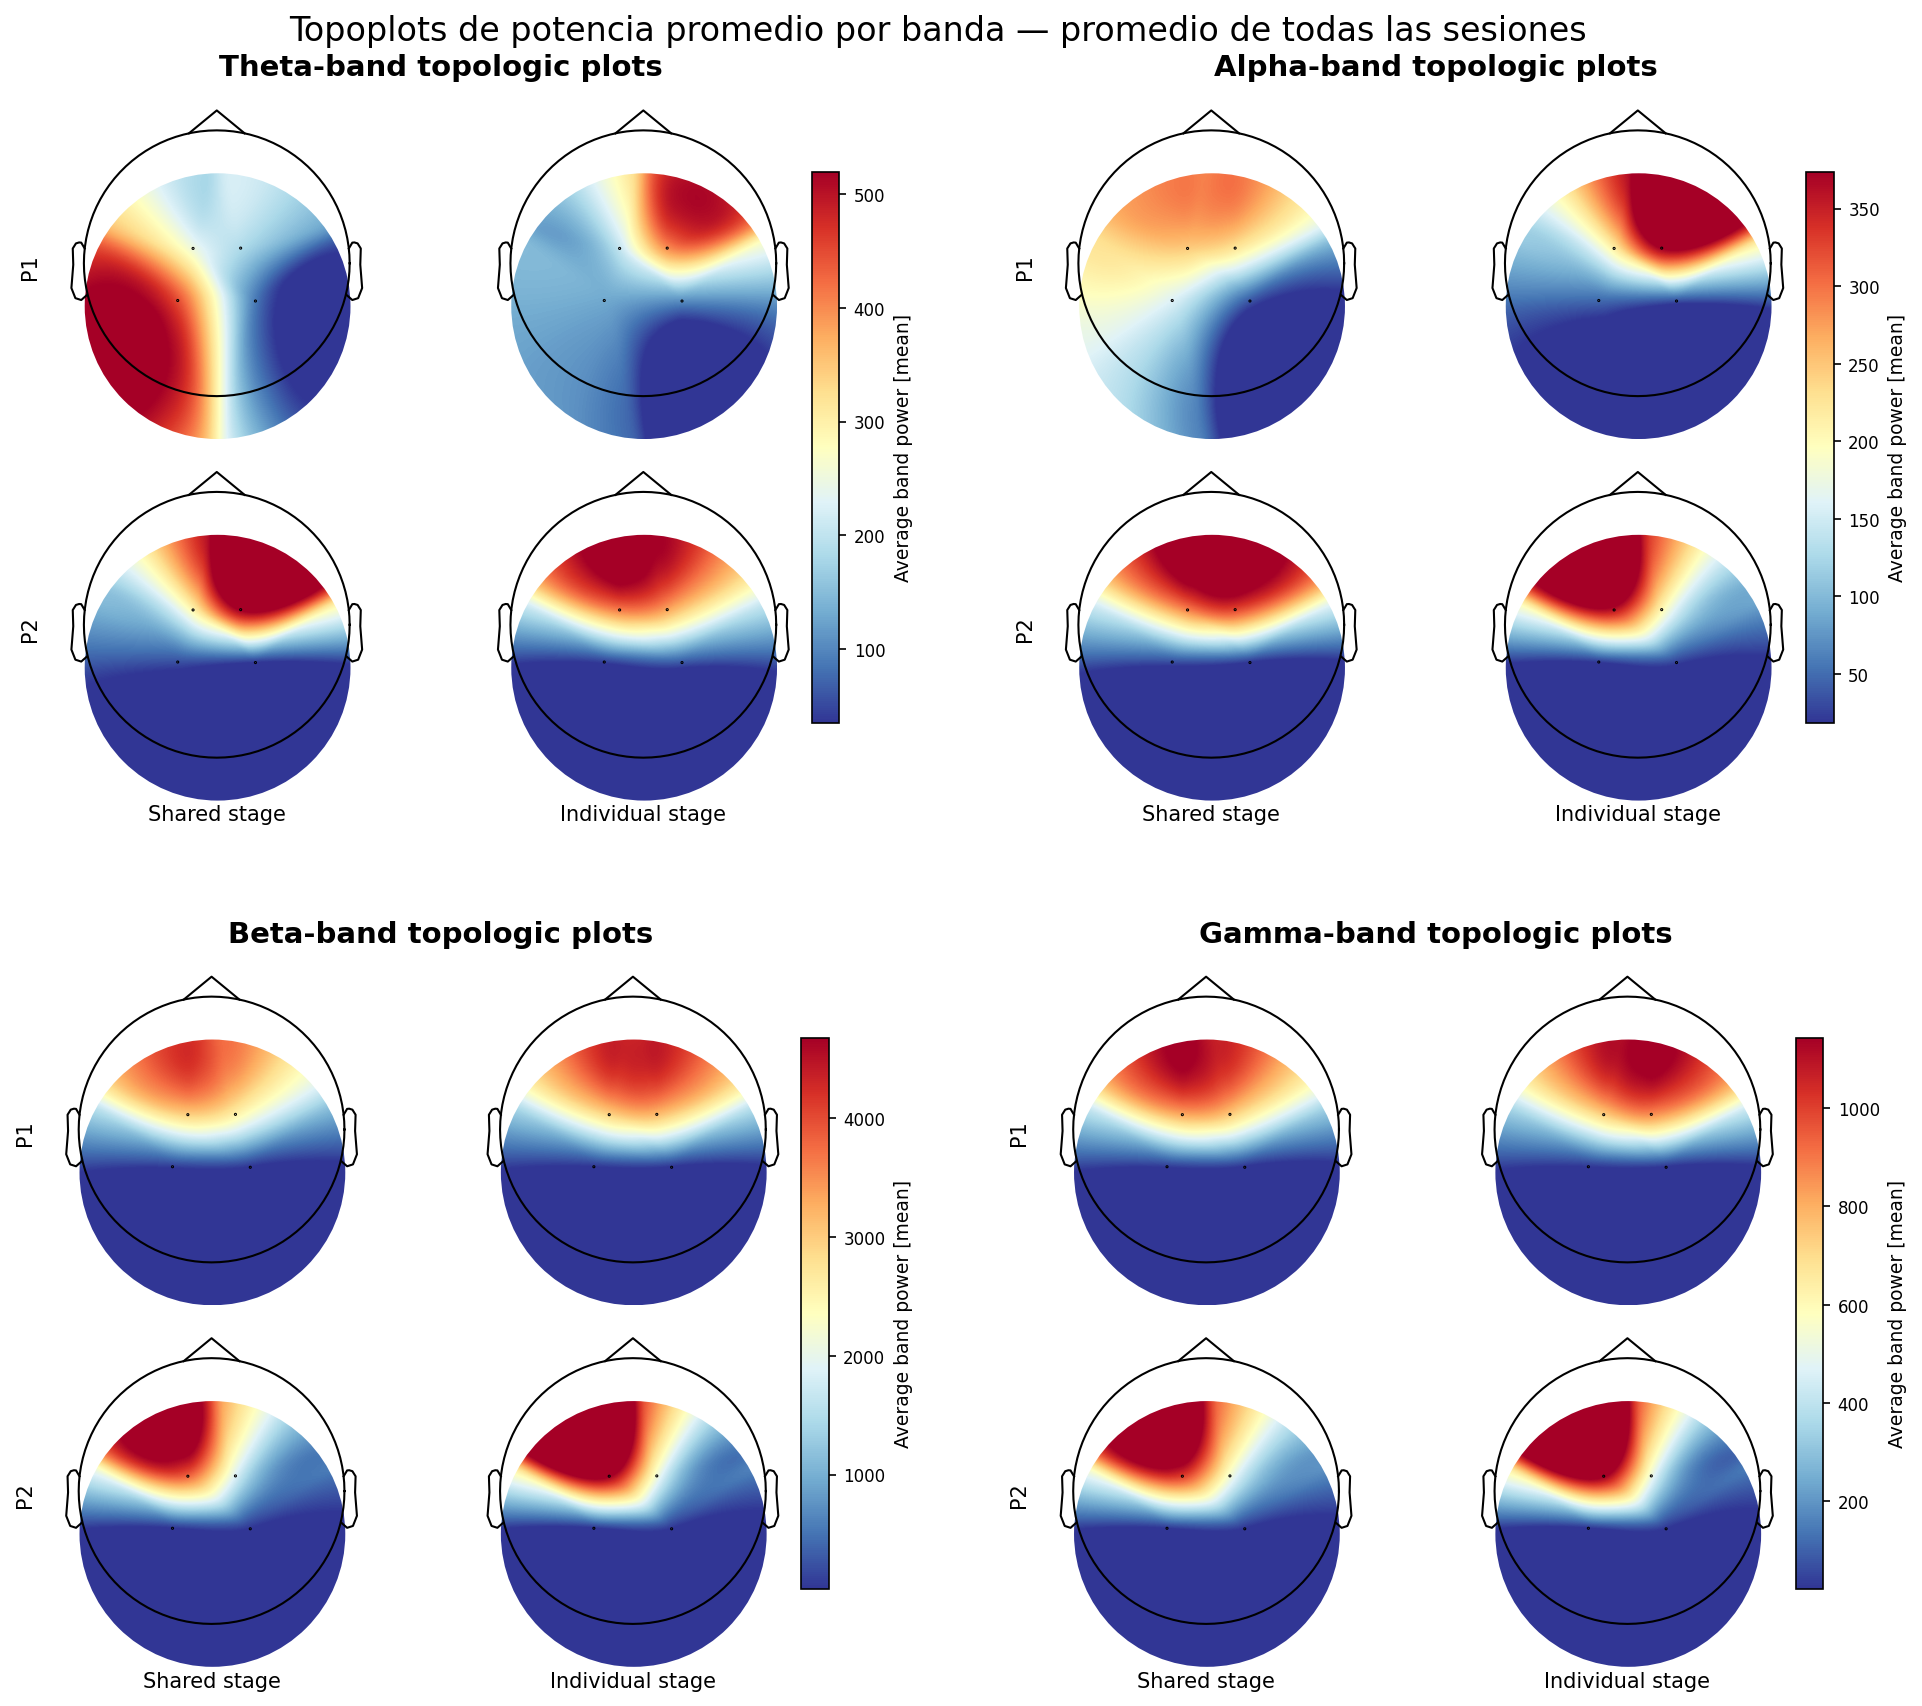

In [18]:
# ============================================================
# FIGURA 1: PROMEDIO DE TODAS LAS SESIONES
# ============================================================

fig_avg = plot_band_topomap_grid(
    metricdata,
    session=None,
    bands=topo_bands,
    participants=topo_participants,
    stages=topo_stages,
    agg="mean",
    scale_scope="band",      # recomendado: misma escala dentro de cada banda
    symmetric_scale=False,
    figsize=(13, 11),
    dpi=150,
)
plt.show()


Sesiones disponibles: [2.0, 12.0, 14.0, 21.0, 27.0, 28.0, 31.0, 39.0, 41.0, 42.0]


C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: Only 4 head digitization points of the specified kinds ("eeg", "extra",), fitting may be inaccurate
  image, _ = mne.viz.plot_topomap(
C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: Estimated head radius (20.0 cm) is above the 99th percentile for adult head size.
  image, _ = mne.viz.plot_topomap(
C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: (X, Y) fit (-1.2, 64.7) more than 20 mm from head frame origin
  image, _ = mne.viz.plot_topomap(
C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: Only 4 head digitization points of the specified kinds ("eeg", "extra",), fitting may be inaccurate
  image, _ = mne.viz.plot_topomap(
C:\Users\josee\AppData\Local\Temp\ipykernel_7592\1951288307.py:156: RuntimeWarning: Estimated head radius (20.0 cm) is above the 99th percentile for adult head size.
  image, _ = 

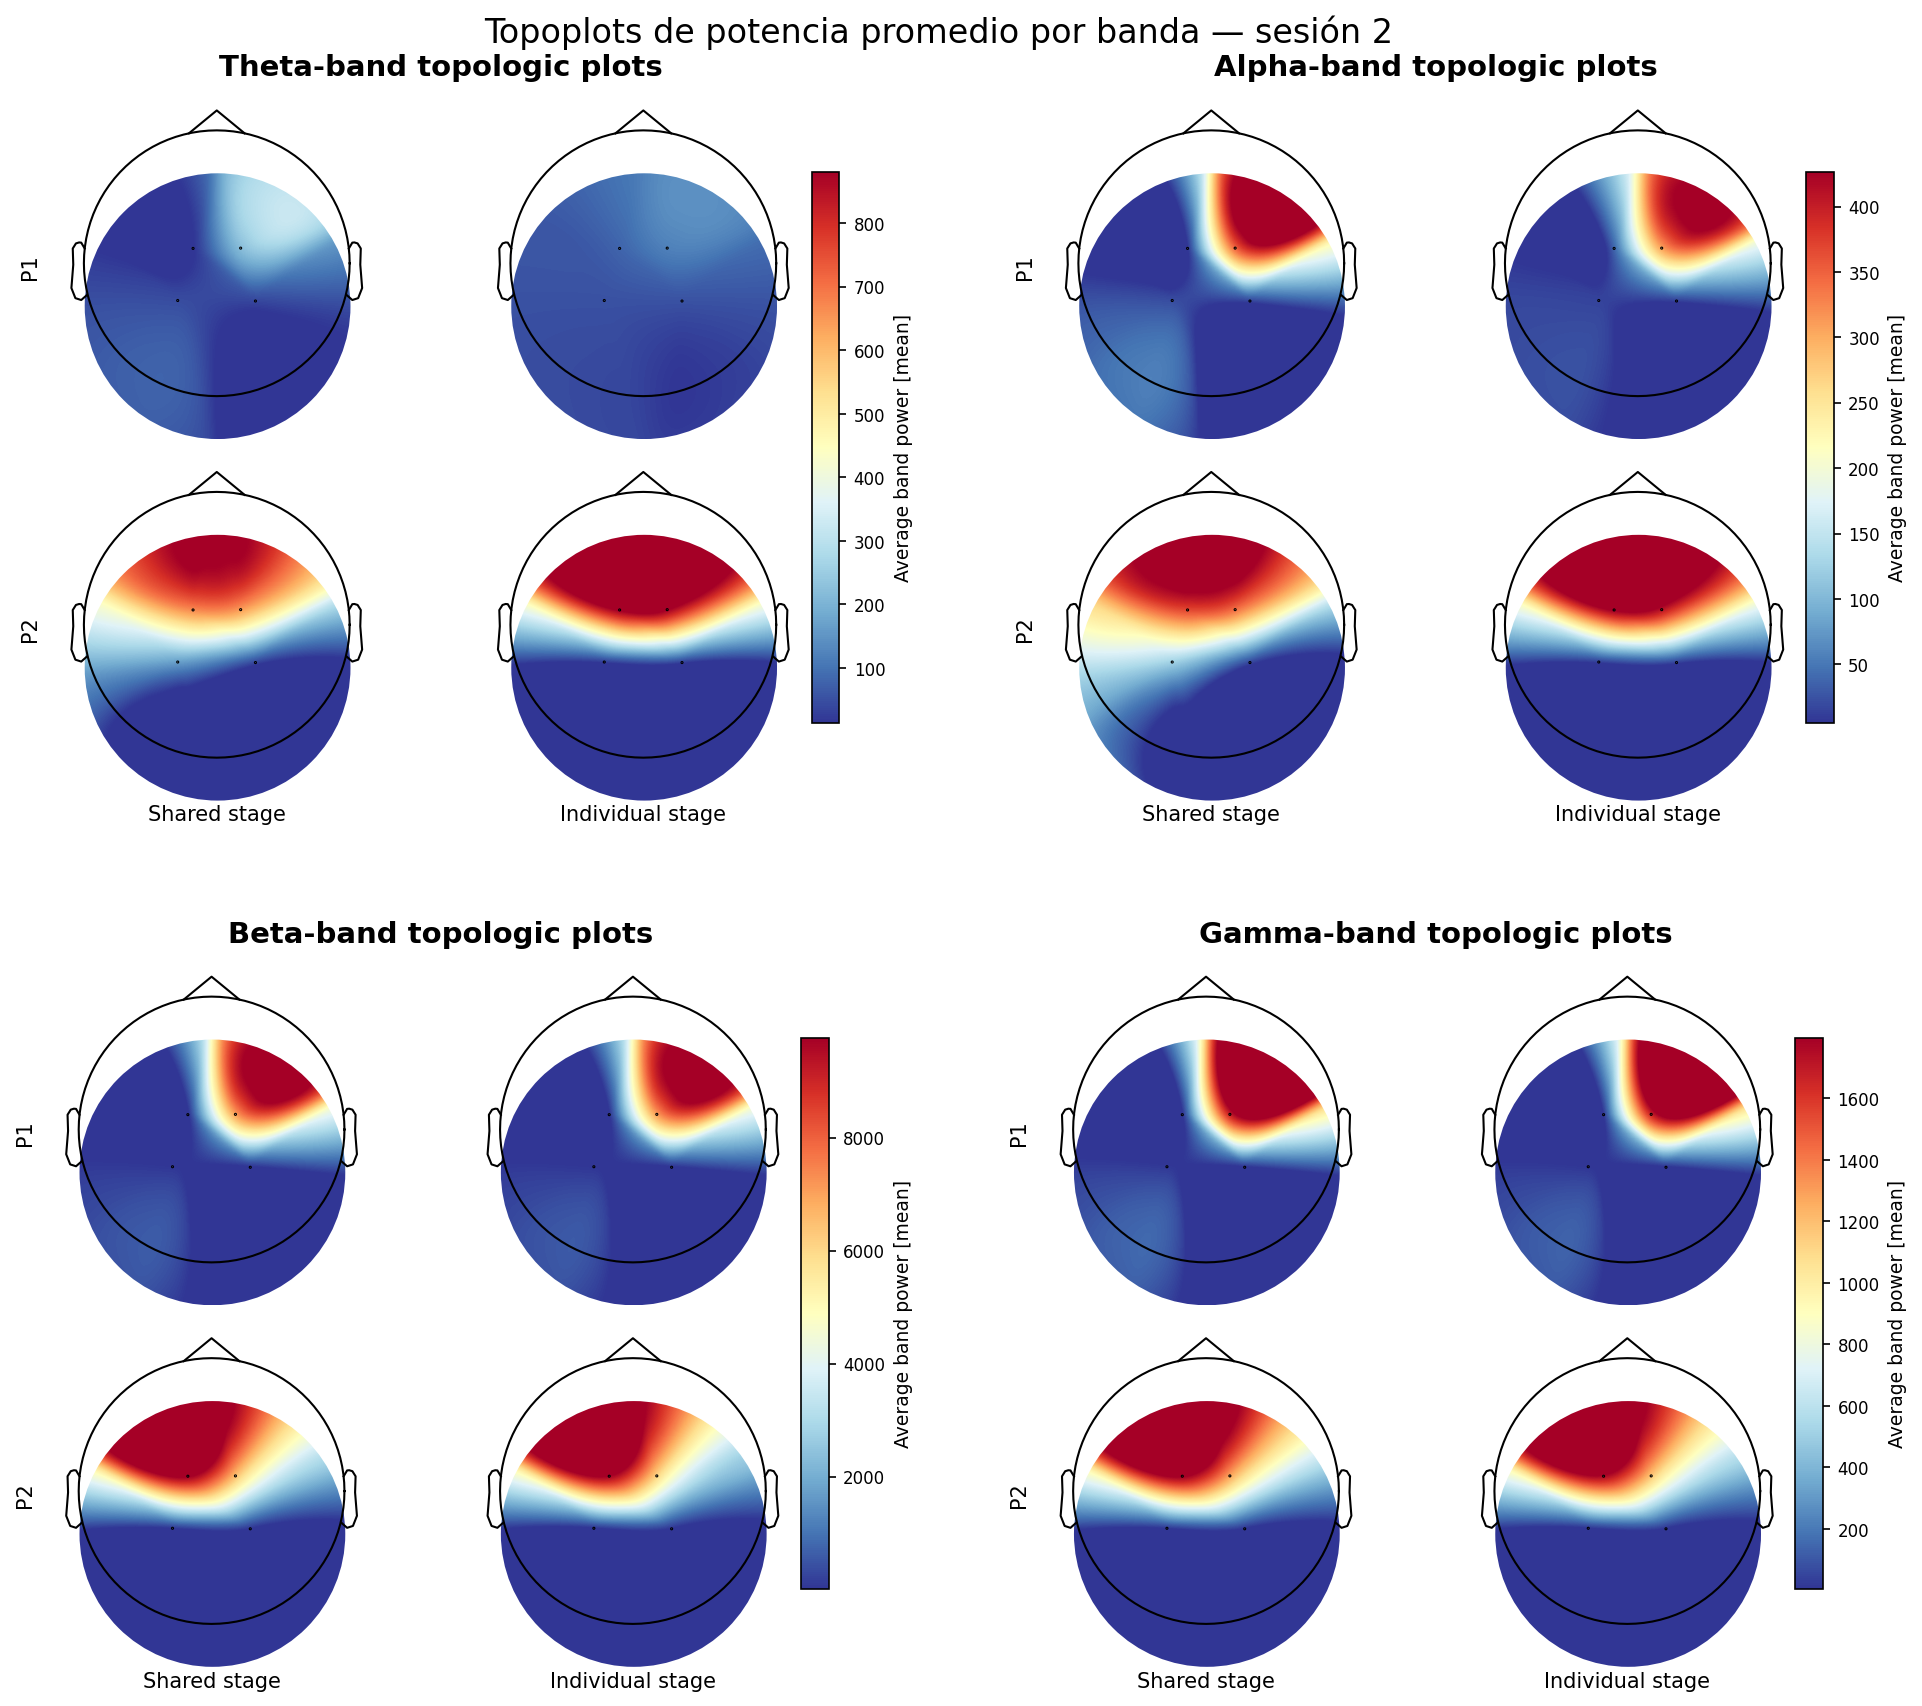

In [19]:
# ============================================================
# FIGURA 2: SESIÓN INDIVIDUAL ELEGIDA MANUALMENTE
# ============================================================

print("Sesiones disponibles:", _available_sessions(metricdata, topo_participants, topo_stages))

session_to_plot = 2  # <-- cambia aquí la sesión que quieres graficar

fig_session = plot_band_topomap_grid(
    metricdata,
    session=session_to_plot,
    bands=topo_bands,
    participants=topo_participants,
    stages=topo_stages,
    agg="mean",
    scale_scope="band",      # recomendado: misma escala dentro de cada banda
    symmetric_scale=False,
    figsize=(13, 11),
    dpi=150,
)
plt.show()
